<a href="https://colab.research.google.com/github/makdiyadaulat/DMBI_EXP_DIPESHMAKDIYA/blob/main/gen_Ai_exp6_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gen AI: Experiment - 6
**Name:** Dipesh Makdiya   
**Division:** D20C  
**Roll No.:** 21

## Experiment Title:
Generative Adversarial Network (GAN) for Synthetic Image Generation.

## Aim:
Implement and evaluate a TensorFlow/Keras GAN on MNIST and study adversarial training.

## Run configuration
This is a fresh CPU execution of a compact variant of the reference DCGAN. It uses a seeded random subset of 12,000 MNIST training images, 50 epochs, batch size 128 and latent dimension 100. Generator channels are 64, 32 and 16; discriminator channels are 16 and 32. The adversarial objective, 28 x 28 outputs and report output categories follow the reference. All saved losses and images below come from this execution. Set TRAIN_LIMIT = 60000 to train on the full dataset; allow more time.

Run all cells in order in Google Colab (GPU recommended) or Jupyter with TensorFlow, NumPy, Matplotlib and Pillow installed. Outputs are written to the current working directory. No API key is needed.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["OMP_NUM_THREADS"] = "4"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import matplotlib.pyplot as plt
import os
import time
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("Name: Dipesh Makdiya | Division: D20C | Roll No: 21")


TensorFlow: 2.21.0
Name: Dipesh Makdiya | Division: D20C | Roll No: 21


In [2]:
# Load MNIST dataset
(x_train, _), (_, _) = keras.datasets.mnist.load_data()

print("Original dataset shape:", x_train.shape)

TRAIN_LIMIT = 12000
indices = np.random.default_rng(42).permutation(len(x_train))[:TRAIN_LIMIT]
x_train = x_train[indices]
print("Training subset:", len(x_train))

# Convert to float32
x_train = x_train.astype("float32")

# Normalize pixel values from [0, 255] to [-1, 1]
x_train = (x_train - 127.5) / 127.5

# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)

print("Preprocessed dataset shape:", x_train.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original dataset shape: (60000, 28, 28)
Training subset: 12000
Preprocessed dataset shape: (12000, 28, 28, 1)
Minimum pixel value: -1.0
Maximum pixel value: 1.0


In [3]:
BUFFER_SIZE = len(x_train)
BATCH_SIZE = 128

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(BUFFER_SIZE, seed=42)
train_dataset = train_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Batch size:", BATCH_SIZE)

Batch size: 128


In [4]:
LATENT_DIM = 100

def build_generator():
    model = keras.Sequential(name="Generator")

    model.add(layers.Input(shape=(LATENT_DIM,)))

    # Project latent vector into a 7x7x64 feature map
    model.add(layers.Dense(7 * 7 * 64, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Reshape((7, 7, 64)))

    # 7x7 -> 7x7
    model.add(
        layers.Conv2DTranspose(
            32,
            kernel_size=5,
            strides=1,
            padding="same",
            use_bias=False
        )
    )
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # 7x7 -> 14x14
    model.add(
        layers.Conv2DTranspose(
            16,
            kernel_size=5,
            strides=2,
            padding="same",
            use_bias=False
        )
    )
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # Output image: 28x28x1
    model.add(
        layers.Conv2DTranspose(
            1,
            kernel_size=5,
            strides=2,
            padding="same",
            activation="tanh"
        )
    )

    return model


generator = build_generator()

generator.summary(line_length=78)

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                     ┃ Output Shape            ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                    │ (None, 3136)            │       313,600 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ batch_normalization              │ (None, 3136)            │        12,544 │
│ (BatchNormalization)             │                         │               │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)          │ (None, 3136)            │             0 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ reshape (Reshape)                │ (None, 7, 7, 64)        │             0 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ conv2d_transpose                 │ (None, 7, 7, 32)        │        51,200 │
│ (Conv2DTranspose)                │                         │               │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ batch_normalization_1            │ (None, 7, 7, 32)        │           128 │
│ (BatchNormalization)             │                         │               │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)        │ (None, 7, 7, 32)        │             0 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ conv2d_transpose_1               │ (None, 14, 14, 16)      │        12,800 │
│ (Conv2DTranspose)                │                         │               │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ batch_normalization_2            │ (None, 14, 14, 16)      │            64 │
│ (BatchNormalization)             │                         │               │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)        │ (None, 14, 14, 16)      │             0 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ conv2d_transpose_2               │ (None, 28, 28, 1)       │           401 │
│ (Conv2DTranspose)                │                         │               │
└──────────────────────────────────┴─────────────────────────┴───────────────┘

 Total params: 390,737 (1.49 MB)

 Trainable params: 384,369 (1.47 MB)

 Non-trainable params: 6,368 (24.88 KB)

In [5]:
def build_discriminator():
    model = keras.Sequential(name="Discriminator")

    model.add(layers.Input(shape=(28, 28, 1)))

    model.add(
        layers.Conv2D(
            16,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(
        layers.Conv2D(
            32,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())

    model.add(layers.Dense(1))

    return model


discriminator = build_discriminator()

discriminator.summary(line_length=78)

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                     ┃ Output Shape            ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                  │ (None, 14, 14, 16)      │           416 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)        │ (None, 14, 14, 16)      │             0 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ dropout (Dropout)                │ (None, 14, 14, 16)      │             0 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)                │ (None, 7, 7, 32)        │        12,832 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)        │ (None, 7, 7, 32)        │             0 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ dropout_1 (Dropout)              │ (None, 7, 7, 32)        │             0 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ flatten (Flatten)                │ (None, 1568)            │             0 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ dense_1 (Dense)                  │ (None, 1)               │         1,569 │
└──────────────────────────────────┴─────────────────────────┴───────────────┘

 Total params: 14,817 (57.88 KB)

 Trainable params: 14,817 (57.88 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Generate random noise
noise = tf.random.normal([16, LATENT_DIM])

# Generate images
generated_images = generator(noise, training=False)

print("Generated image shape:", generated_images.shape)

Generated image shape: (16, 28, 28, 1)


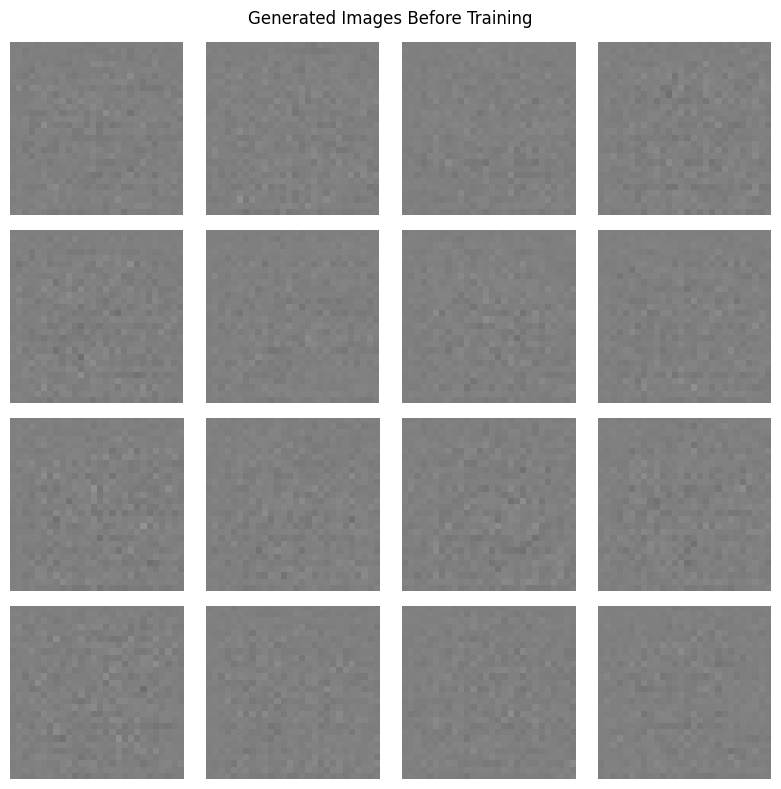

In [7]:
def display_images(images, title="Generated Images"):
    images = (images + 1) / 2.0

    plt.figure(figsize=(8, 8))

    for i in range(min(16, len(images))):
        plt.subplot(4, 4, i + 1)
        plt.imshow(images[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
        plt.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


display_images(
    generated_images,
    title="Generated Images Before Training"
)

In [8]:
cross_entropy = keras.losses.BinaryCrossentropy(from_logits=True)


def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    total_loss = real_loss + fake_loss

    return total_loss


def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

In [9]:
generator_optimizer = keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

In [10]:
NUM_EXAMPLES_TO_GENERATE = 16

seed = tf.random.normal(
    [NUM_EXAMPLES_TO_GENERATE, LATENT_DIM]
)

print("Fixed seed shape:", seed.shape)

Fixed seed shape: (16, 100)


In [11]:
@tf.function
def train_step(images):

    noise = tf.random.normal(
        [tf.shape(images)[0], LATENT_DIM]
    )

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        generated_images = generator(
            noise,
            training=True
        )

        real_output = discriminator(
            images,
            training=True
        )

        fake_output = discriminator(
            generated_images,
            training=True
        )

        gen_loss = generator_loss(fake_output)

        disc_loss = discriminator_loss(
            real_output,
            fake_output
        )

    gradients_of_generator = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    gradients_of_discriminator = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            gradients_of_generator,
            generator.trainable_variables
        )
    )

    discriminator_optimizer.apply_gradients(
        zip(
            gradients_of_discriminator,
            discriminator.trainable_variables
        )
    )

    return gen_loss, disc_loss

In [12]:
os.makedirs("generated_images", exist_ok=True)


def generate_and_save_images(model, epoch, test_input):

    predictions = model(
        test_input,
        training=False
    )

    predictions = (predictions + 1) / 2.0

    plt.figure(figsize=(8, 8))

    for i in range(16):
        plt.subplot(4, 4, i + 1)

        plt.imshow(
            predictions[i, :, :, 0],
            cmap="gray", vmin=0, vmax=1
        )

        plt.axis("off")

    plt.suptitle(
        f"Generated Images - Epoch {epoch}"
    )

    plt.tight_layout()

    filename = f"generated_images/epoch_{epoch:03d}.png"

    plt.savefig(
        filename,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print("Saved:", filename)

Epoch 01/50 | Generator Loss: 0.5618 | Discriminator Loss: 1.1548 | Time: 21.98s


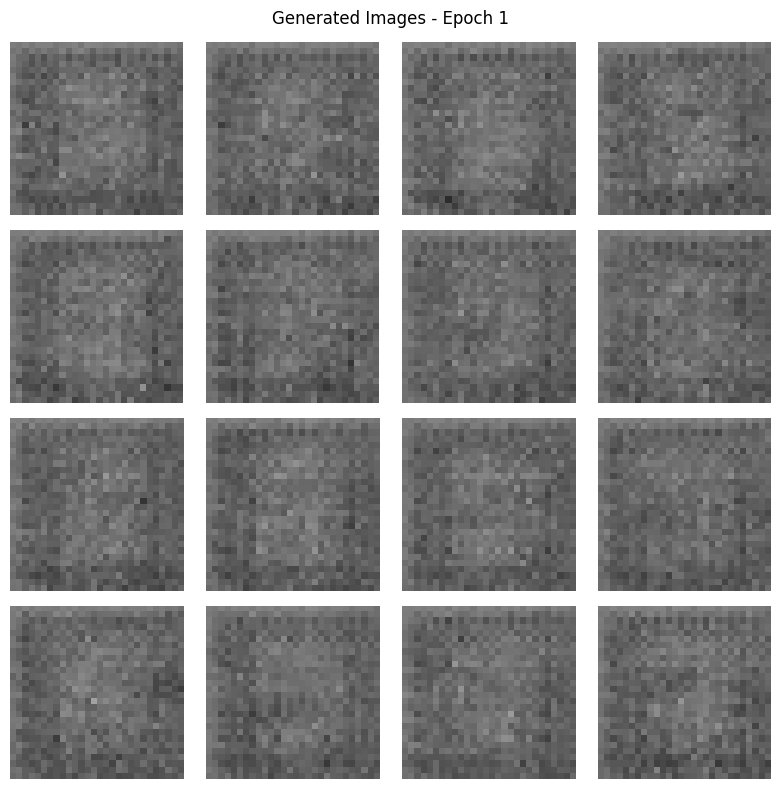

Saved: generated_images/epoch_001.png
Epoch 02/50 | Generator Loss: 0.7464 | Discriminator Loss: 1.1056 | Time: 20.46s
Epoch 03/50 | Generator Loss: 0.8869 | Discriminator Loss: 1.0567 | Time: 17.16s
Epoch 04/50 | Generator Loss: 0.8767 | Discriminator Loss: 1.1538 | Time: 17.21s
Epoch 05/50 | Generator Loss: 0.8684 | Discriminator Loss: 1.1980 | Time: 18.76s


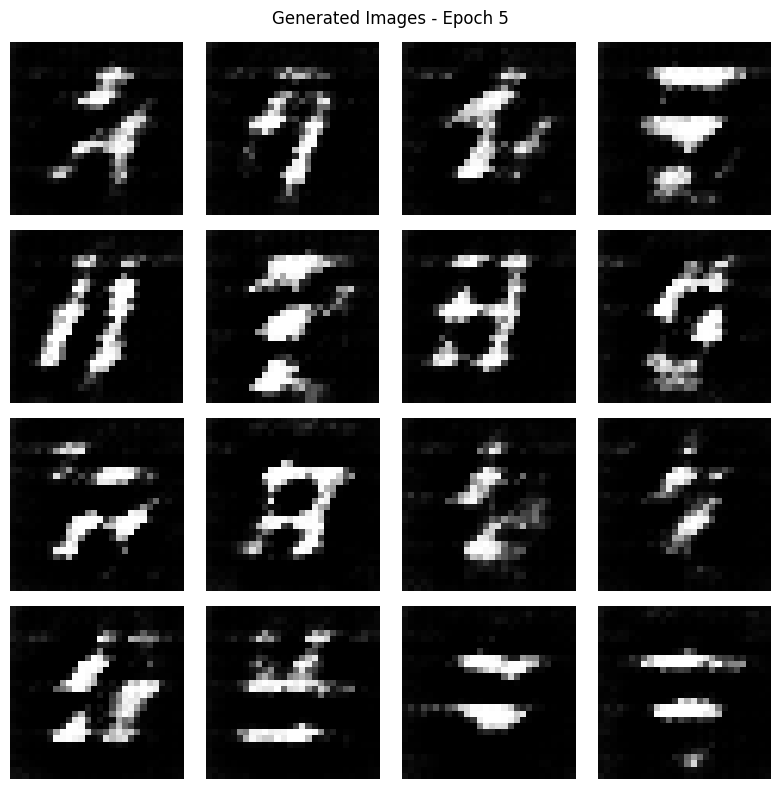

Saved: generated_images/epoch_005.png
Epoch 06/50 | Generator Loss: 0.8443 | Discriminator Loss: 1.2607 | Time: 17.13s
Epoch 07/50 | Generator Loss: 0.8145 | Discriminator Loss: 1.2879 | Time: 17.19s
Epoch 08/50 | Generator Loss: 0.7926 | Discriminator Loss: 1.3191 | Time: 20.47s
Epoch 09/50 | Generator Loss: 0.7926 | Discriminator Loss: 1.3027 | Time: 17.20s
Epoch 10/50 | Generator Loss: 0.7780 | Discriminator Loss: 1.3277 | Time: 17.14s


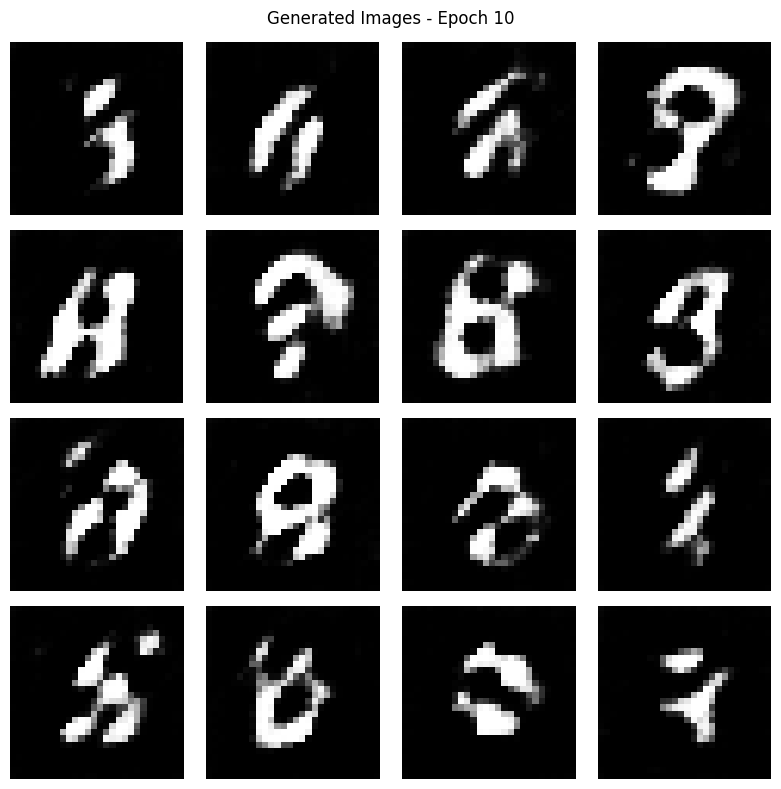

Saved: generated_images/epoch_010.png
Epoch 11/50 | Generator Loss: 0.7609 | Discriminator Loss: 1.3502 | Time: 18.64s
Epoch 12/50 | Generator Loss: 0.7696 | Discriminator Loss: 1.3164 | Time: 17.30s
Epoch 13/50 | Generator Loss: 0.7540 | Discriminator Loss: 1.3592 | Time: 17.18s
Epoch 14/50 | Generator Loss: 0.7523 | Discriminator Loss: 1.3452 | Time: 18.81s
Epoch 15/50 | Generator Loss: 0.7575 | Discriminator Loss: 1.3323 | Time: 17.21s
Epoch 16/50 | Generator Loss: 0.7446 | Discriminator Loss: 1.3464 | Time: 17.36s
Epoch 17/50 | Generator Loss: 0.7460 | Discriminator Loss: 1.3507 | Time: 18.29s
Epoch 18/50 | Generator Loss: 0.7441 | Discriminator Loss: 1.3595 | Time: 17.70s
Epoch 19/50 | Generator Loss: 0.7401 | Discriminator Loss: 1.3557 | Time: 17.19s
Epoch 20/50 | Generator Loss: 0.7458 | Discriminator Loss: 1.3446 | Time: 17.16s


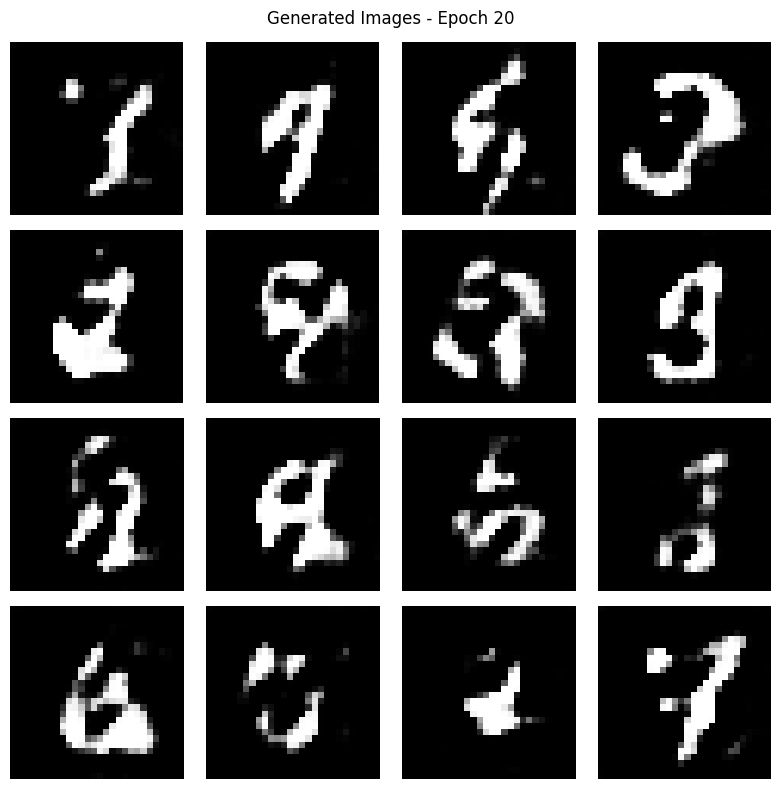

Saved: generated_images/epoch_020.png
Epoch 21/50 | Generator Loss: 0.7411 | Discriminator Loss: 1.3472 | Time: 18.68s
Epoch 22/50 | Generator Loss: 0.7434 | Discriminator Loss: 1.3482 | Time: 17.64s
Epoch 23/50 | Generator Loss: 0.7402 | Discriminator Loss: 1.3536 | Time: 17.58s
Epoch 24/50 | Generator Loss: 0.7486 | Discriminator Loss: 1.3451 | Time: 18.64s
Epoch 25/50 | Generator Loss: 0.7461 | Discriminator Loss: 1.3443 | Time: 17.25s
Epoch 26/50 | Generator Loss: 0.7528 | Discriminator Loss: 1.3412 | Time: 17.36s
Epoch 27/50 | Generator Loss: 0.7621 | Discriminator Loss: 1.3218 | Time: 18.75s
Epoch 28/50 | Generator Loss: 0.7578 | Discriminator Loss: 1.3343 | Time: 17.24s
Epoch 29/50 | Generator Loss: 0.7671 | Discriminator Loss: 1.3204 | Time: 17.31s
Epoch 30/50 | Generator Loss: 0.7729 | Discriminator Loss: 1.3164 | Time: 19.03s


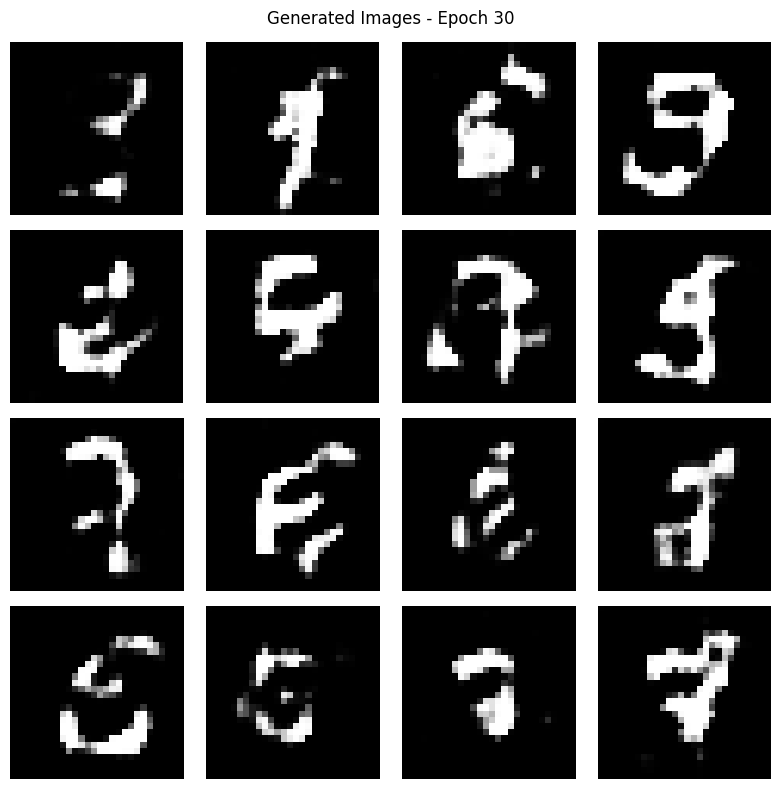

Saved: generated_images/epoch_030.png
Epoch 31/50 | Generator Loss: 0.7805 | Discriminator Loss: 1.3171 | Time: 17.37s
Epoch 32/50 | Generator Loss: 0.7831 | Discriminator Loss: 1.3051 | Time: 17.24s
Epoch 33/50 | Generator Loss: 0.7862 | Discriminator Loss: 1.3011 | Time: 18.90s
Epoch 34/50 | Generator Loss: 0.7892 | Discriminator Loss: 1.3091 | Time: 17.19s
Epoch 35/50 | Generator Loss: 0.8042 | Discriminator Loss: 1.2858 | Time: 17.26s
Epoch 36/50 | Generator Loss: 0.7878 | Discriminator Loss: 1.3084 | Time: 18.13s
Epoch 37/50 | Generator Loss: 0.7877 | Discriminator Loss: 1.3044 | Time: 17.70s
Epoch 38/50 | Generator Loss: 0.7889 | Discriminator Loss: 1.3131 | Time: 17.49s
Epoch 39/50 | Generator Loss: 0.7806 | Discriminator Loss: 1.3163 | Time: 20.47s
Epoch 40/50 | Generator Loss: 0.7817 | Discriminator Loss: 1.3256 | Time: 17.17s


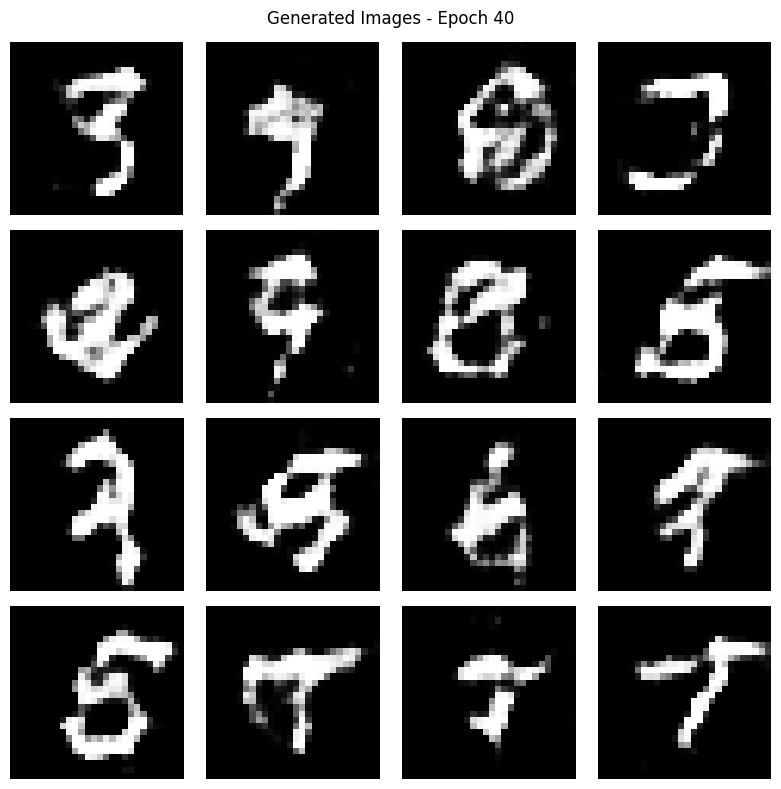

Saved: generated_images/epoch_040.png
Epoch 41/50 | Generator Loss: 0.7809 | Discriminator Loss: 1.3089 | Time: 17.13s
Epoch 42/50 | Generator Loss: 0.7763 | Discriminator Loss: 1.3428 | Time: 18.79s
Epoch 43/50 | Generator Loss: 0.7754 | Discriminator Loss: 1.3219 | Time: 17.18s
Epoch 44/50 | Generator Loss: 0.7680 | Discriminator Loss: 1.3318 | Time: 17.26s
Epoch 45/50 | Generator Loss: 0.7698 | Discriminator Loss: 1.3407 | Time: 20.47s
Epoch 46/50 | Generator Loss: 0.7566 | Discriminator Loss: 1.3458 | Time: 17.23s
Epoch 47/50 | Generator Loss: 0.7663 | Discriminator Loss: 1.3314 | Time: 17.13s
Epoch 48/50 | Generator Loss: 0.7594 | Discriminator Loss: 1.3407 | Time: 18.78s
Epoch 49/50 | Generator Loss: 0.7595 | Discriminator Loss: 1.3397 | Time: 17.28s
Epoch 50/50 | Generator Loss: 0.7549 | Discriminator Loss: 1.3432 | Time: 17.13s


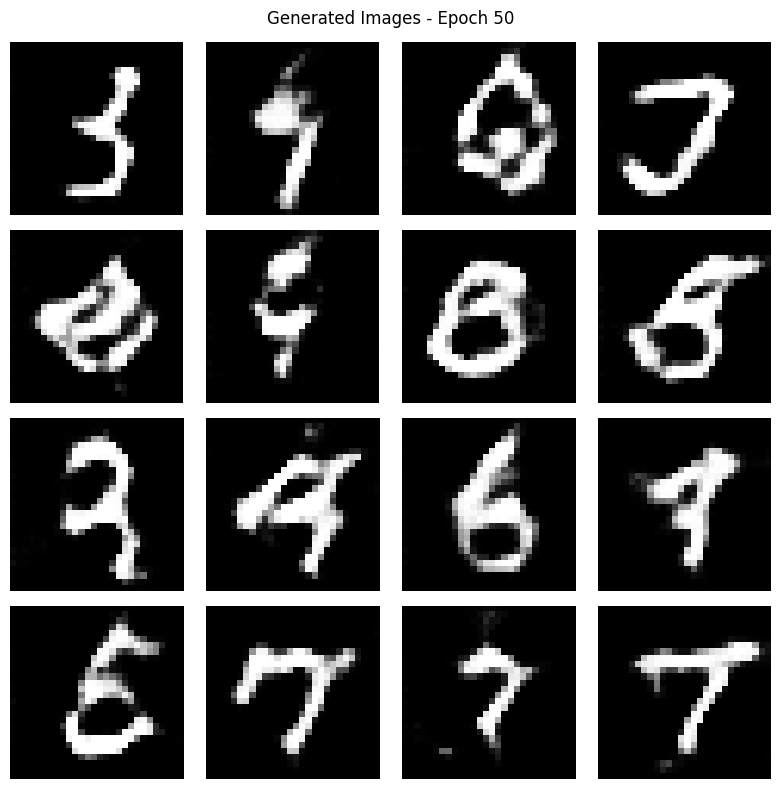

Saved: generated_images/epoch_050.png

Total Training Time: 15.06 minutes


In [13]:
import time

EPOCHS = 50

generator_losses = []
discriminator_losses = []

start_time = time.time()

for epoch in range(1, EPOCHS + 1):

    epoch_start = time.time()

    gen_loss_total = 0
    disc_loss_total = 0
    batches = 0

    for image_batch in train_dataset:

        gen_loss, disc_loss = train_step(image_batch)

        gen_loss_total += float(gen_loss) * len(image_batch)
        disc_loss_total += float(disc_loss) * len(image_batch)

        batches += len(image_batch)

    avg_gen_loss = gen_loss_total / batches
    avg_disc_loss = disc_loss_total / batches

    generator_losses.append(float(avg_gen_loss))
    discriminator_losses.append(float(avg_disc_loss))

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Generator Loss: {avg_gen_loss:.4f} | "
        f"Discriminator Loss: {avg_disc_loss:.4f} | "
        f"Time: {time.time() - epoch_start:.2f}s"
    )

    # Save images at selected epochs
    if epoch in [1, 5, 10, 20, 30, 40, 50]:
        generate_and_save_images(
            generator,
            epoch,
            seed
        )

total_training_time = time.time() - start_time

print(
    f"\nTotal Training Time: "
    f"{total_training_time / 60:.2f} minutes"
)

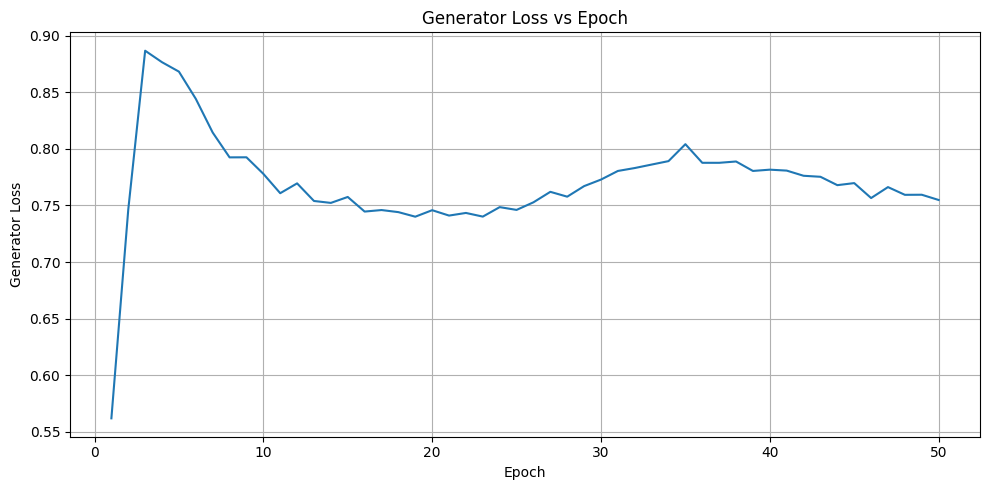

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    generator_losses
)

plt.xlabel("Epoch")
plt.ylabel("Generator Loss")
plt.title("Generator Loss vs Epoch")

plt.grid(True)
plt.tight_layout()

plt.savefig(
    "generator_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

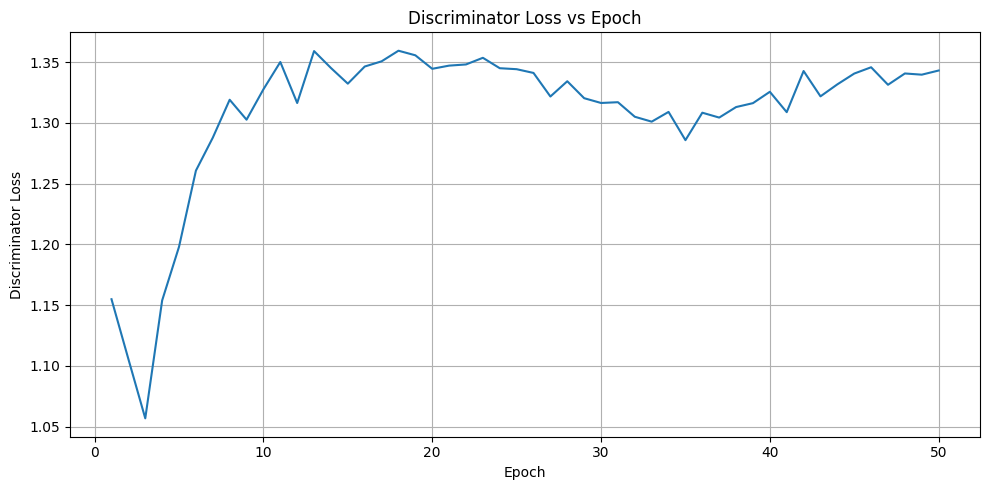

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    discriminator_losses
)

plt.xlabel("Epoch")
plt.ylabel("Discriminator Loss")
plt.title("Discriminator Loss vs Epoch")

plt.grid(True)
plt.tight_layout()

plt.savefig(
    "discriminator_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

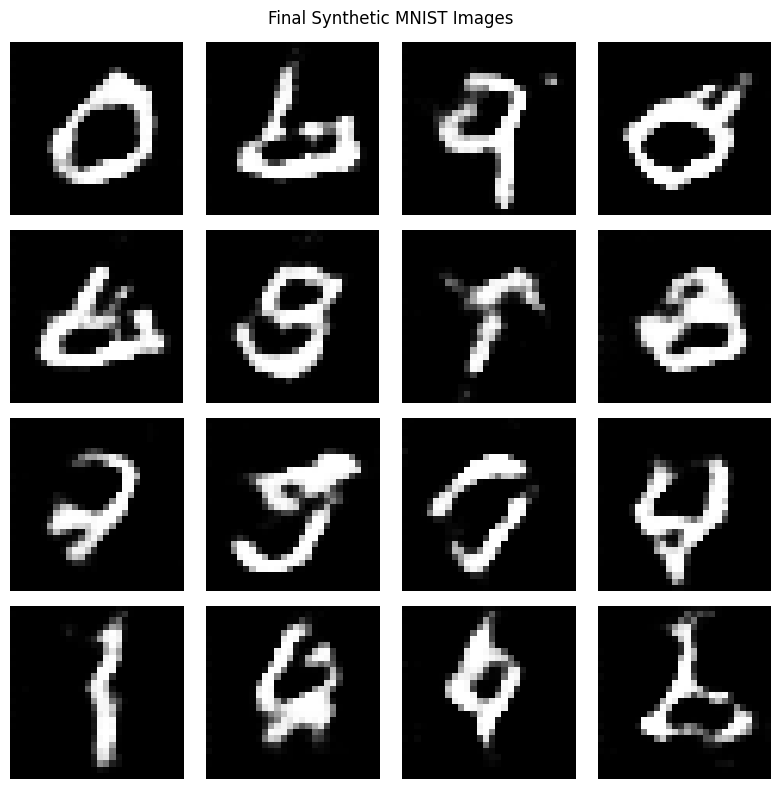

In [16]:
final_noise = tf.random.normal(
    [16, LATENT_DIM]
)

final_images = generator(
    final_noise,
    training=False
)

display_images(
    final_images,
    title="Final Synthetic MNIST Images"
)

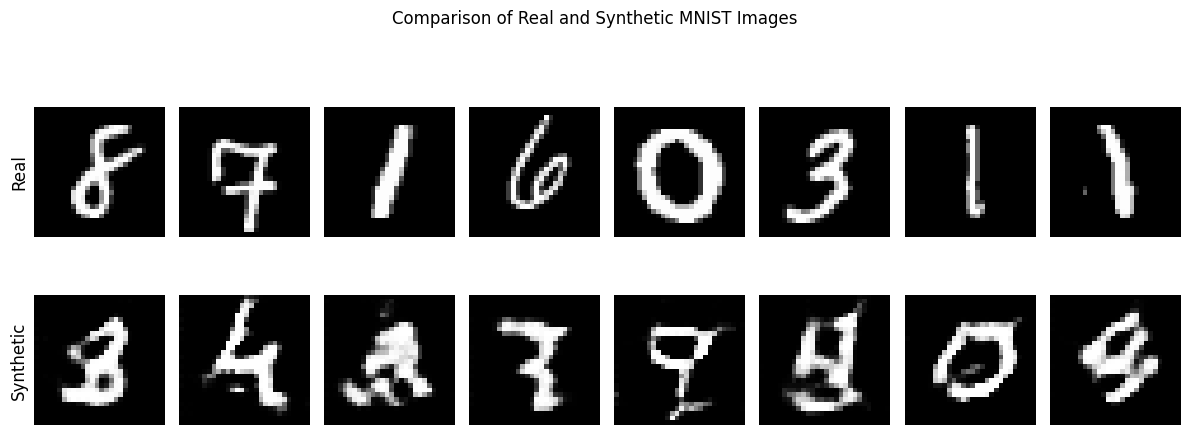

In [17]:
# Select 8 real images
real_images = x_train[:8]

# Generate 8 synthetic images
noise = tf.random.normal([8, LATENT_DIM])

synthetic_images = generator(
    noise,
    training=False
).numpy()

# Convert from [-1,1] to [0,1]
real_images_display = (real_images + 1) / 2.0
synthetic_images_display = (synthetic_images + 1) / 2.0

plt.figure(figsize=(12, 5))

for i in range(8):

    # Real image
    plt.subplot(2, 8, i + 1)

    plt.imshow(
        real_images_display[i, :, :, 0],
        cmap="gray", vmin=0, vmax=1
    )

    plt.xticks([])
    plt.yticks([])
    plt.box(False)

    if i == 0:
        plt.ylabel(
            "Real",
            fontsize=12
        )

    # Synthetic image
    plt.subplot(2, 8, i + 9)

    plt.imshow(
        synthetic_images_display[i, :, :, 0],
        cmap="gray", vmin=0, vmax=1
    )

    plt.xticks([])
    plt.yticks([])
    plt.box(False)

    if i == 0:
        plt.ylabel(
            "Synthetic",
            fontsize=12
        )

plt.suptitle(
    "Comparison of Real and Synthetic MNIST Images"
)

plt.tight_layout()

plt.savefig(
    "real_vs_synthetic.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
print("========== FINAL GAN RESULTS ==========")

print(f"Total Epochs: {EPOCHS}")

print(
    f"Final Generator Loss: "
    f"{generator_losses[-1]:.6f}"
)

print(
    f"Final Discriminator Loss: "
    f"{discriminator_losses[-1]:.6f}"
)

print(
    f"Minimum Generator Loss: "
    f"{min(generator_losses):.6f}"
)

print(
    f"Minimum Discriminator Loss: "
    f"{min(discriminator_losses):.6f}"
)

print(
    f"Maximum Generator Loss: "
    f"{max(generator_losses):.6f}"
)

print(
    f"Maximum Discriminator Loss: "
    f"{max(discriminator_losses):.6f}"
)

print(
    f"Total Training Time: "
    f"{total_training_time / 60:.2f} minutes"
)

========== FINAL GAN RESULTS ==========
Total Epochs: 50
Final Generator Loss: 0.754869
Final Discriminator Loss: 1.343166
Minimum Generator Loss: 0.561764
Minimum Discriminator Loss: 1.056739
Maximum Generator Loss: 0.886876
Maximum Discriminator Loss: 1.359474
Total Training Time: 15.06 minutes


In [19]:
import json
from pathlib import Path
history = {"generator_losses": generator_losses,
           "discriminator_losses": discriminator_losses,
           "training_seconds": total_training_time,
           "epochs": EPOCHS, "training_images": len(x_train),
           "generator_parameters": generator.count_params(),
           "discriminator_parameters": discriminator.count_params()}
Path("training_history.json").write_text(json.dumps(history, indent=2))
generator.save("mnist_generator.keras")
discriminator.save("mnist_discriminator.keras")
print("Saved training history and both trained models.")

Saved training history and both trained models.
